# Customer Intelligence & Support Copilot
## Instructor-led end-to-end notebook

**Scenario:** synthetic grocery quick-commerce data. This notebook emphasizes *how data is fetched, inspected, cleaned, validated, stored, and then consumed by downstream AI/ML components*.

### Before class
1. Run `python generate_data.py` from the repository root.
2. Install packages with `pip install -r requirements.txt`.
3. Run this notebook from the repository root so relative paths work.

All data and policies are fictional. The LLM calls are handled by `mock_llm.py` locally; no API key is required.

## 0. Repository map and end-to-end flow

`generate_data.py` → `data/raw/*.csv` → audit → clean → `data/clean/*.csv` + `data/instamart.db` → RFM/segments + lapse model → privacy-safe ticket triage → policy retrieval + refund tools.

Teaching point: **fetching data** does not always mean calling an API. Here, the source is a local CSV export. In a production system, the same ingestion layer could use an approved API or warehouse connector, but credentials and network access are intentionally out of scope.

### Coverage map: brief → notebook

| Brief part | Where in this notebook |
|---|---|
| **Part A** — Data foundation | §1–§4: generate, audit, clean, validate, SQLite |
| **Part B** — Segmentation & churn | §5: RFM, K-means, silhouette, PCA, churn (lapse) model + validation summary |
| **Part C** — Ticket triage | §6: guardrails, PII redaction, classification, routing, output dictionary |
| **Part D** — Policy RAG & co-pilot | §7 policy retrieval · §8 refund / order tools and human escalation |
| Reproducibility | §9: generated artifacts check |

In [3]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "generate_data.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)
print("Root files:", sorted(p.name for p in ROOT.iterdir() if p.is_file()))

Project root: c:\Users\ASWIN\Desktop_New\Aswin\Swiggy-Instamart-Copilot-main\instamart_customer_copilot_teaching_kit
Root files: ['.gitignore', 'GITHUB_RESOURCES.md', 'README.md', 'generate_data.py', 'mock_llm.py', 'requirements.txt', 'run_project.py']


## 1. Part A — Generate / fetch the raw data

The data generator is deterministic (fixed random seed). It writes customer, product, order, support-ticket, evaluation-question, agent-scenario inputs and policy text files.

Run it once when starting from a clean clone. Running it again recreates the same synthetic source exports.

In [4]:
import subprocess, sys
subprocess.run([sys.executable, str(ROOT / "generate_data.py")], check=True, cwd=ROOT)
raw_dir = ROOT / "data" / "raw"
print("Raw files:", sorted(p.name for p in raw_dir.iterdir()))

Raw files: ['customers.csv', 'orders.csv', 'policy_eval.csv', 'products.csv', 'tickets.csv']


## 2. Part A — Read the exports and understand their shape

Use `keep_default_na=False` for ticket text so empty strings remain empty strings. This is important because empty tickets must be identified by an explicit guardrail rather than silently changing the input representation.

In [5]:
import pandas as pd
customers_raw = pd.read_csv(raw_dir / "customers.csv", keep_default_na=False)
products_raw = pd.read_csv(raw_dir / "products.csv", keep_default_na=False)
orders_raw = pd.read_csv(raw_dir / "orders.csv", keep_default_na=False)
tickets_raw = pd.read_csv(raw_dir / "tickets.csv", keep_default_na=False)

for name, df in [("customers", customers_raw), ("products", products_raw),
                 ("orders", orders_raw), ("tickets", tickets_raw)]:
    print(f"\\n{name}: shape={df.shape}")
    display(df.head(3))
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "blank_count": df.astype(str).apply(lambda col: col.str.strip().eq("").sum()),
        "missing_pct": (df.isna().mean() * 100).round(2)
    }))

\ncustomers: shape=(1200, 5)


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35,MALE
1,C0002,DELHI,2024-02-17,31,MALE
2,C0003,bengaluru,2025-02-18,18,F


,dtype,missing_count,blank_count,missing_pct
customer_id,str,0,0,0.0
city,str,0,0,0.0
signup_date,str,0,0,0.0
age,str,0,61,0.0
gender,str,0,30,0.0


\nproducts: shape=(40, 4)


,product_id,product_name,category,price_inr
0,P001,Basmati Rice 1kg,Grocery,129
1,P002,Toor Dal 1kg,Grocery,165
2,P003,Atta 5kg,Grocery,245


,dtype,missing_count,blank_count,missing_pct
product_id,str,0,0,0.0
product_name,str,0,0,0.0
category,str,0,0,0.0
price_inr,int64,0,0,0.0


... (2 outputs left out)

,dtype,missing_count,blank_count,missing_pct
order_id,str,0,0,0.0
customer_id,str,0,0,0.0
product_id,str,0,0,0.0
quantity,int64,0,0,0.0
order_ts,str,0,0,0.0
status,str,0,0,0.0
discount_pct,int64,0,0,0.0
order_amount,str,0,0,0.0
delivery_minutes,str,0,2541,0.0


\ntickets: shape=(164, 5)


,ticket_id,customer_id,order_id,text,true_category
0,T0024,C0486,ORD-105035,There is an unauthorized transaction on my car...,fraud
1,T0073,C0080,ORD-100816,The invoice for ORD-100816 shows a wrong amoun...,billing
2,T0095,C1087,ORD-111156,The payment page shows an error and the app fr...,technical


,dtype,missing_count,blank_count,missing_pct
ticket_id,str,0,0,0.0
customer_id,str,0,0,0.0
order_id,str,0,8,0.0
text,str,0,4,0.0
true_category,str,0,0,0.0


### Audit questions for students
- Which columns are supposed to be unique keys?
- Are duplicates exact duplicates or multiple states of the same order?
- Which values are impossible (negative delivery duration, non-numeric money, implausible age)?
- Why should we distinguish an empty string from a missing value?
- What would go wrong if we modelled before cleaning?

In [6]:
# Practical audit answering the discussion questions:
orders_raw = pd.read_csv(raw_dir / "orders.csv", keep_default_na=False)
customers_raw = pd.read_csv(raw_dir / "customers.csv", keep_default_na=False)

# 1. Key uniqueness and duplicate states check:
exact_dups = orders_raw.duplicated().sum()
distinct_ids = orders_raw['order_id'].nunique()
state_dups = len(orders_raw) - distinct_ids
print(f"Orders: total={len(orders_raw)}, unique_order_ids={distinct_ids}, exact_duplicates={exact_dups}, state_updates={state_dups - exact_dups}")

# 2. Impossible values inspection (negative delivery, bad order amounts, impossible age):
raw_delivery = pd.to_numeric(orders_raw['delivery_minutes'], errors='coerce')
raw_amount = pd.to_numeric(orders_raw['order_amount'], errors='coerce')
raw_age = pd.to_numeric(customers_raw['age'], errors='coerce')

print(f"Negative delivery durations (< 0): {(raw_delivery < 0).sum()}")
print(f"Invalid order amounts (non-numeric): {raw_amount.isna().sum()}")
print(f"Implausible ages (<10 or >100): {((raw_age < 10) | (raw_age > 100)).sum()}")
print(f"Cancelled orders with blank delivery: {orders_raw.loc[orders_raw['status'] == 'cancelled', 'delivery_minutes'].eq('').sum()}")


Orders: total=13084, unique_order_ids=12309, exact_duplicates=119, state_updates=656
Negative delivery durations (< 0): 106
Invalid order amounts (non-numeric): 120
Implausible ages (<10 or >100): 6
Cancelled orders with blank delivery: 1211


In [7]:
from src.data_pipeline import audit, clean_data, validate
audit()


customers: shape=(1200, 5)
customer_id    str
city           str
signup_date    str
age            str
gender         str
dtype: object
             missing_count  missing_pct
customer_id              0          0.0
city                     0          0.0
signup_date              0          0.0
age                      0          0.0
gender                   0          0.0

products: shape=(40, 4)
product_id        str
product_name      str
category          str
price_inr       int64
dtype: object
              missing_count  missing_pct
product_id                0          0.0
product_name              0          0.0
category                  0          0.0
price_inr                 0          0.0

orders: shape=(13084, 9)
order_id              str
customer_id           str
product_id            str
quantity            int64
order_ts              str
status                str
discount_pct        int64
order_amount          str
delivery_minutes      str
dtype: object
                 

## 3. Part A — Clean the data and write trusted outputs

The pipeline applies explicit rules:
- standardize city and gender;
- make impossible ages missing and fill with city median;
- parse timestamps, remove exact duplicates, then keep the latest row per order ID;
- coerce invalid amounts to missing and calculate replacements from product price × quantity × discount;
- set negative delivery times to missing and impute only completed orders using product-category medians;
- save clean CSVs and SQLite tables.

Ask students to explain why cancelled orders should keep a missing delivery duration.

In [8]:
clean = clean_data()
for name, df in clean.items():
    print(name, df.shape)
    display(df.head(3))
validate()

customers (1200, 5)


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35,male
1,C0002,Delhi,2024-02-17,31,male
2,C0003,Bengaluru,2025-02-18,18,female


products (40, 4)


,product_id,product_name,category,price_inr
0,P001,Basmati Rice 1kg,Grocery,129
1,P002,Toor Dal 1kg,Grocery,165
2,P003,Atta 5kg,Grocery,245


orders (12309, 9)


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes
827,ORD-100001,C0001,P001,1,2025-09-16 08:07:21,completed,15,109.65,20
4294,ORD-100002,C0001,P008,1,2025-09-03 07:34:01,completed,40,25.20,23
9973,ORD-100003,C0001,P008,1,2025-04-08 17:08:14,completed,0,42.00,23


ALL CHECKPOINTS PASSED


## 4. Part A — Query the SQLite database

The clean tables are persisted in `data/instamart.db`. SQLite gives us a portable analytical database that can be queried without setting up a server.

Run the supplied SQL examples and compare SQL totals to pandas results.

In [9]:
import sqlite3
db_path = ROOT / "data" / "instamart.db"
with sqlite3.connect(db_path) as con:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con)
    display(tables)
    q2 = pd.read_sql_query("""
        SELECT c.city, p.category, ROUND(SUM(o.order_amount), 2) AS revenue
        FROM orders o
        JOIN customers c USING(customer_id)
        JOIN products p USING(product_id)
        WHERE o.status = 'completed'
        GROUP BY c.city, p.category
        ORDER BY c.city, p.category
    """, con)
    display(q2.head(10))
    sql_total = round(q2.revenue.sum(), 2)
    print("SQL grand total INR:", sql_total)

# Compare SQL result with pandas directly to verify analytical consistency:
orders_clean = pd.read_csv(ROOT / "data" / "clean" / "orders.csv")
pandas_total = round(orders_clean.loc[orders_clean['status'] == 'completed', 'order_amount'].sum(), 2)
print("Pandas grand total INR:", pandas_total)
assert abs(sql_total - pandas_total) < 1.0, "Mismatch between SQL and Pandas totals!"
print("✓ SQL and Pandas totals match perfectly!")

,name
0,customers
1,orders
2,products


,city,category,revenue
0,Bengaluru,Dairy,87075.05
1,Bengaluru,Electronics,233909.45
2,Bengaluru,Grocery,110915.65
3,Bengaluru,Personal Care,20193.85
4,Bengaluru,Snacks,71549.40
5,Chennai,Dairy,78301.80
6,Chennai,Electronics,195508.80
7,Chennai,Grocery,93817.45
8,Chennai,Personal Care,27675.40
9,Chennai,Snacks,68325.70


SQL grand total INR: 2998668.8
Pandas grand total INR: 2998668.8
✓ SQL and Pandas totals match perfectly!


## 5. Part B — Customer Segmentation and Churn Prediction

RFM means:
- **Recency:** days since the most recent completed order at the snapshot date.
- **Frequency:** number of distinct completed orders.
- **Monetary:** total spend across completed orders.

The model module scales RFM for K-means, compares K values, uses PCA to inspect compressed variance, and builds a lapse model. The lapse model's input features use only orders before 2025-09-01; September is reserved to define the label. The scaler and encoder are fitted inside a training pipeline, not on the test data.

**Churn vs. lapse:** the brief calls the second task *churn prediction*. In this notebook the churn target is implemented as a **lapse** label — customers who place **no completed order in September 2025** (features use only orders before 2025-09-01). `build_lapse_model()` is therefore the churn model.

**Validation (brief requirement):** segmentation quality is checked with silhouette scores and PCA explained variance; the churn model is compared with a baseline that predicts nobody lapses. The two cells after the model cell summarise and plot these.

In [10]:
from src.customer_models import rfm_and_segments, build_lapse_model
rfm, k_diagnostics, segment_profile, pca_variance = rfm_and_segments(k=4)
display(k_diagnostics.round(3))
display(segment_profile.round(2))
print("PCA explained variance ratio:", pca_variance, "total:", pca_variance.sum())
display(rfm.head())
lapse_summary = build_lapse_model()
lapse_summary

,k,inertia,silhouette
0,2,1820.761,0.465
1,3,1268.235,0.445
2,4,743.071,0.526
3,5,617.367,0.480
4,6,503.171,0.482
5,7,408.460,0.416
6,8,366.503,0.412


,segment_id,size,recency,frequency,monetary
0,0,436,28.86,3.77,1057.62
1,1,138,24.12,6.77,7129.70
2,2,419,8.77,19.40,3410.02
3,3,182,109.04,2.20,685.99


PCA explained variance ratio: [0.63427875 0.21803762] total: 0.8523163667502165


,customer_id,frequency,monetary,recency,segment_id,segment_name,is_premium
0,C0001,4,512.85,14,0,At Risk,False
1,C0002,7,4644.90,28,1,Premium,True
2,C0003,22,3644.85,7,2,Frequent,False
3,C0004,5,369.00,0,0,At Risk,False
4,C0005,2,324.00,147,3,At Risk,False


{'cohort_rows': 1156,
 'lapsed': 443,
 'baseline_accuracy': 0.6163793103448276,
 'models': {'logistic': {'best_params': {'model__C': 100},
   'cv_f1': np.float64(0.650552962900789),
   'precision': 0.6444444444444445,
   'recall': 0.651685393258427,
   'f1': 0.6480446927374302,
   'confusion_matrix': [[111, 32], [31, 58]]},
  'forest': {'best_params': {'model__max_depth': 8,
    'model__min_samples_leaf': 10},
   'cv_f1': np.float64(0.6865517479789224),
   'precision': 0.6333333333333333,
   'recall': 0.6404494382022472,
   'f1': 0.6368715083798883,
   'confusion_matrix': [[110, 33], [32, 57]]}},
 'retention_list':     customer_id  lapse_probability  actually_lapsed
 13        C0862           0.510513                0
 190       C0267           0.477212                0
 165       C1008           0.473260                0
 227       C0060           0.471746                0
 5         C0802           0.471582                0
 216       C0942           0.465245                0
 144   

In [11]:
# Part B validation summary - built only from objects returned by the cell above
# (rfm, k_diagnostics, segment_profile, pca_variance, lapse_summary).
import numpy as np

# 1) Segmentation quality: silhouette score
chosen_k = len(segment_profile)
chosen_sil = k_diagnostics.loc[k_diagnostics["k"] == chosen_k, "silhouette"].iloc[0]
best = k_diagnostics.loc[k_diagnostics["silhouette"].idxmax()]
print(f"K used for segments: {chosen_k} | silhouette = {chosen_sil:.3f}")
print(f"Highest silhouette over tested K: K={int(best['k'])} ({best['silhouette']:.3f})")

# 2) PCA variance explained
print("PCA explained variance ratio:", np.round(pca_variance, 3))
print(f"{len(pca_variance)} components explain {pca_variance.sum():.1%} of the RFM variance")

# 3) How segment IDs map to business names
print("\nSegment id vs segment name (customer counts):")
display(pd.crosstab(rfm["segment_id"], rfm["segment_name"]))

# 4) Churn (lapse) model vs. a baseline that predicts nobody lapses
cohort, lapsed = lapse_summary["cohort_rows"], lapse_summary["lapsed"]
print(f"Lapse (churn) rate in modelling cohort: {lapsed}/{cohort} = {lapsed / cohort:.1%}")
print(f"Baseline accuracy, predicting nobody lapses (test set): {lapse_summary['baseline_accuracy']:.3f}")

rows = []
for name, m in lapse_summary["models"].items():
    (tn, fp), (fn, tp) = m["confusion_matrix"]          # sklearn layout [[TN, FP], [FN, TP]]
    rows.append({
        "model": name,
        "accuracy": (tn + tp) / (tn + fp + fn + tp),
        "precision": m["precision"],
        "recall": m["recall"],
        "f1": m["f1"],
        "cv_f1": float(m["cv_f1"]),
    })
display(pd.DataFrame(rows).set_index("model").round(3))

K used for segments: 4 | silhouette = 0.526
Highest silhouette over tested K: K=4 (0.526)
PCA explained variance ratio: [0.634 0.218]
2 components explain 85.2% of the RFM variance

Segment id vs segment name (customer counts):


segment_name,At Risk,Frequent,Premium
segment_id,,,
0,436,0,0
1,0,0,138
2,0,419,0
3,182,0,0


Lapse (churn) rate in modelling cohort: 443/1156 = 38.3%
Baseline accuracy, predicting nobody lapses (test set): 0.616


,accuracy,precision,recall,f1,cv_f1
model,,,,,
logistic,0.728,0.644,0.652,0.648,0.651
forest,0.720,0.633,0.640,0.637,0.687


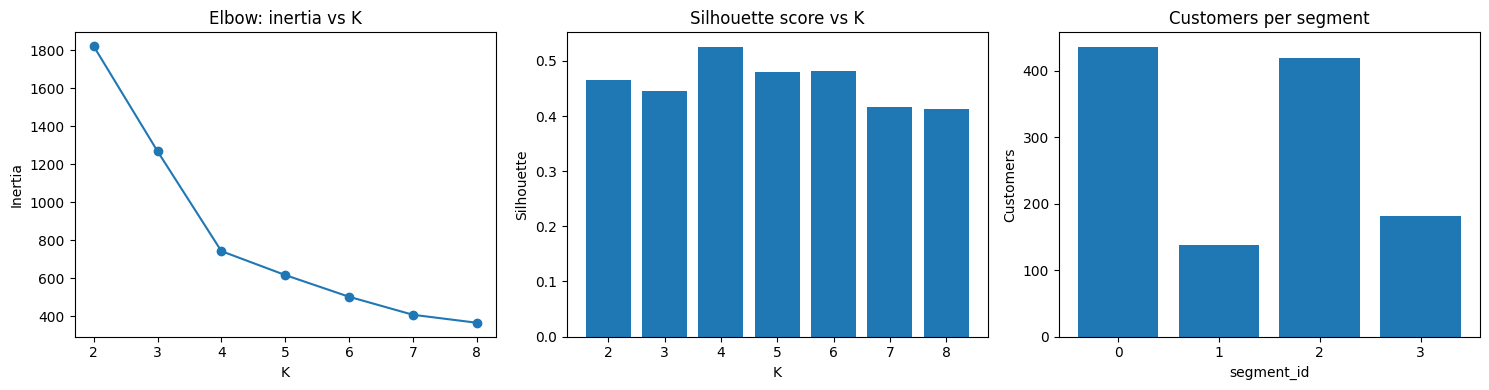

In [12]:
# Part B charts: elbow, silhouette by K, segment sizes
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("matplotlib is not installed - add it to requirements.txt to see the charts.")

if plt is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(k_diagnostics["k"], k_diagnostics["inertia"], marker="o")
    axes[0].set_title("Elbow: inertia vs K")
    axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")

    axes[1].bar(k_diagnostics["k"], k_diagnostics["silhouette"])
    axes[1].set_title("Silhouette score vs K")
    axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette")

    axes[2].bar(segment_profile["segment_id"].astype(str), segment_profile["size"])
    axes[2].set_title("Customers per segment")
    axes[2].set_xlabel("segment_id"); axes[2].set_ylabel("Customers")

    plt.tight_layout()
    plt.show()

### Instructor discussion: leakage
Ask students to identify:
1. Which dates can enter the lapse-model features?
2. Why must September orders not enter the features?
3. Why is a Premium-only retention list labelled *illustrative* if the Premium flag comes from whole-window RFM?
4. Why can accuracy be misleading when a substantial minority of customers lapse?
5. What do the silhouette score and the PCA explained variance tell you about the chosen K?

## 6. Part C — support ticket triage

This pipeline demonstrates:
1. input guardrails for empty and overlong tickets;
2. ordered PII redaction (email → phone → order ID);
3. retry logic for simulated transient errors;
4. strict category validation and a keyword fallback;
5. token budgeting and human-review routing.

The exact user message sent to the mock classifier is the redacted ticket text only.

In [13]:
from src.triage import run_pipeline, FEW, ZERO
triage_results, triage_summary = run_pipeline(prompt=FEW, token_budget=100000)
print(triage_summary)
display(triage_results.head(10))
display(triage_results.status.value_counts().rename_axis("status").reset_index(name="tickets"))

retry ticket=T0002 retry=0 wait=0.0530s
retry ticket=T0116 retry=0 wait=0.0453s
retry ticket=T0153 retry=0 wait=0.0484s
retry ticket=T0039 retry=0 wait=0.0478s
retry ticket=T0152 retry=0 wait=0.0542s
retry ticket=T0043 retry=0 wait=0.0535s
retry ticket=T0111 retry=0 wait=0.0562s
retry ticket=T0155 retry=0 wait=0.0461s
retry ticket=T0100 retry=0 wait=0.0503s
retry ticket=T0068 retry=0 wait=0.0454s
retry ticket=T0135 retry=0 wait=0.0477s
retry ticket=T0009 retry=0 wait=0.0513s
retry ticket=T0067 retry=0 wait=0.0453s
retry ticket=T0106 retry=0 wait=0.0475s
retry ticket=T0097 retry=0 wait=0.0531s
retry ticket=T0003 retry=0 wait=0.0518s
retry ticket=T0019 retry=0 wait=0.0478s
retry ticket=T0086 retry=0 wait=0.0524s
retry ticket=T0065 retry=0 wait=0.0551s
{'tokens': 12520, 'redactions': {'email': 55, 'phone': 91, 'order_id': 132}, 'status_counts': {'classified_json': 135, 'classified_keyword': 12, 'flagged_invalid_output': 9, 'skipped_empty': 4, 'flagged_long': 4}}


,ticket_id,customer_id,status,category,segment_name,priority,route,tokens_used
0,T0024,C0486,classified_json,fraud,At Risk,HIGH,security_team,84
1,T0073,C0080,classified_json,billing,Frequent,NORMAL,support_queue,80
2,T0095,C1087,classified_json,technical,At Risk,NORMAL,support_queue,82
3,T0159,C1172,skipped_empty,,Frequent,NORMAL,human_review,0
4,T0080,C0910,classified_json,fraud,At Risk,HIGH,security_team,84
5,T0124,C0139,classified_json,fraud,Frequent,HIGH,security_team,84
6,T0061,C0812,classified_json,billing,Frequent,NORMAL,support_queue,76
7,T0118,C0355,classified_json,delivery,Frequent,NORMAL,support_queue,79
8,T0037,C1156,classified_json,billing,Premium,HIGH,premium_desk,80
9,T0002,C0881,classified_json,delivery,At Risk,NORMAL,support_queue,78


,status,tickets
0,classified_json,135
1,classified_keyword,12
2,flagged_invalid_output,9
3,skipped_empty,4
4,flagged_long,4


In [14]:
# Part C - output dictionary: ticket details + routing decision (per the brief)
detail_cols = ["customer_id", "status", "category", "segment_name", "priority", "route"]
triage_output = triage_results.set_index("ticket_id")[detail_cols].to_dict(orient="index")
print(f"{len(triage_output)} tickets in output dictionary (triage rows: {len(triage_results)})")
for ticket_id in list(triage_output)[:3]:
    print(ticket_id, triage_output[ticket_id])

print("\nRoute distribution:")
display(triage_results["route"].value_counts().rename_axis("route").reset_index(name="tickets"))

# Compare predicted category with the labelled historical tickets (true_category).
# Note: mock_llm.py is a keyword-rule classifier and the tickets are templated, so a very high match
# here shows the pipeline wiring works - it is not evidence of real-world LLM accuracy.
eval_df = triage_results.merge(tickets_raw[["ticket_id", "true_category"]], on="ticket_id", how="left")
classified = eval_df[eval_df["status"].str.startswith("classified")]
match = (classified["category"].str.strip().str.lower()
         == classified["true_category"].str.strip().str.lower())
print(f"\nClassified tickets: {len(classified)} | match true_category: {int(match.sum())} ({match.mean():.1%})")
display(pd.crosstab(classified["true_category"], classified["category"]))

164 tickets in output dictionary (triage rows: 164)
T0024 {'customer_id': 'C0486', 'status': 'classified_json', 'category': 'fraud', 'segment_name': 'At Risk', 'priority': 'HIGH', 'route': 'security_team'}
T0073 {'customer_id': 'C0080', 'status': 'classified_json', 'category': 'billing', 'segment_name': 'Frequent', 'priority': 'NORMAL', 'route': 'support_queue'}
T0095 {'customer_id': 'C1087', 'status': 'classified_json', 'category': 'technical', 'segment_name': 'At Risk', 'priority': 'NORMAL', 'route': 'support_queue'}

Route distribution:


,route,tickets
0,support_queue,102
1,security_team,34
2,human_review,17
3,premium_desk,11



Classified tickets: 147 | match true_category: 147 (100.0%)


category,billing,delivery,fraud,technical
true_category,,,,
billing,38,0,0,0
delivery,0,36,0,0
fraud,0,0,34,0
technical,0,0,0,39


### Discussion: privacy and safety
- Redaction is a defence-in-depth step, not a guarantee that every sensitive detail is removed.
- Why are invalid categories sent to human review instead of guessed?
- Why should fraud override ordinary customer-segment routing?
- Why do empty/long tickets need to be blocked before any model call?

## 7. Part D — policy RAG

The retrieval layer chunks policy documents, fits a TF-IDF vectorizer and ranks chunks by cosine similarity. It passes retrieved chunks to the offline policy assistant, which should answer only from the context and fall back when a question is not covered.

In [15]:
from src.policy_rag import PolicyRAG, evaluate
rag = PolicyRAG(chunk_size=40, overlap=10)
print("Policy chunks:", len(rag.chunks))
display(pd.DataFrame(rag.chunks).head())
print(rag.answer("What delivery time makes a completed order eligible for a full refund?"))
policy_eval = evaluate(rag)
display(policy_eval)
print("Expected-document hits:", int(policy_eval.retrieved_doc.sum()))
print("Expected-fact hits:", int(policy_eval.fact_found.sum()))
print("Fallbacks:", int(policy_eval.fallback.sum()))

Policy chunks: 15


,source,text
0,delivery_policy.txt,Delivery Policy. Standard delivery is promised...
1,delivery_policy.txt,"of INR 25 is charged on orders below INR 199, ..."
2,delivery_policy.txt,60 minutes and the app shows a rain notice. A ...
3,escalation_policy.txt,Escalation Policy. A ticket about fraud or an ...
4,escalation_policy.txt,"1 hour, and all other tickets within 24 hours...."


{'answer': 'order is delivered in more than 45 minutes, the customer receives a full refund of the order amount.', 'sources': ['refund_policy.txt', 'privacy_policy.txt'], 'retrieved': [{'source': 'refund_policy.txt', 'score': 0.35464416504570484, 'text': 'order is delivered in more than 45 minutes, the customer receives a full refund of the order amount. If a completed order is delivered in 45 minutes or less, no late-delivery refund is paid. Refunds up to INR 1000 are'}, {'source': 'refund_policy.txt', 'score': 0.31425507733397284, 'text': 'Refund Policy. A refund can be requested only for orders whose status is completed. Orders with status cancelled were never charged, so no refund applies to them. If a completed order is delivered in more than 45 minutes, the customer'}, {'source': 'privacy_policy.txt', 'score': 0.15759666156595936, 'text': 'Delivery addresses are deleted from active systems 180 days after the last order. A customer can ask for account deletion and the request is c

,question,expected_doc,retrieved_doc,fact_found,fallback
0,What delivery time makes a completed order eli...,refund_policy.txt,True,True,False
1,Who must approve a refund above INR 1000?,refund_policy.txt,True,True,False
2,How many days do I have to raise a refund requ...,refund_policy.txt,True,True,False
3,What is the delivery fee on small orders?,delivery_policy.txt,True,True,False
4,On orders of what value is delivery free?,delivery_policy.txt,True,True,False
5,Why does the electronics delivery need a one t...,delivery_policy.txt,True,True,False
6,Is cash on delivery available for a large order?,payment_policy.txt,True,True,False
7,How soon is money returned when a payment fail...,payment_policy.txt,True,True,False
8,Can wallet balance be refunded as cash?,payment_policy.txt,True,True,False
9,When are delivery addresses deleted from activ...,privacy_policy.txt,True,True,False


Expected-document hits: 12
Expected-fact hits: 12
Fallbacks: 2


## 8. Part D — refund tools and safe stopping

The refund agent demonstrates a tool loop: look up an order in SQLite, retrieve policy, calculate the eligible refund, then issue it or escalate to a human. In this teaching kit the ledger is a local JSONL file; no money moves.

Before running agent demonstrations, inspect `src/refund_agent.py` and ask students to trace how a tool name maps to a Python function.

In [16]:
from src.refund_agent import get_order, search_policy, calculate_refund, TOOL_MAP, run_agent
print("Tools:", sorted(TOOL_MAP))
print("Example order lookup:")
with sqlite3.connect(db_path) as con:
    example_order = pd.read_sql_query(
        "SELECT order_id FROM orders WHERE status='completed' AND delivery_minutes > 45 LIMIT 1", con
    ).iloc[0, 0]
print(example_order, get_order(example_order))
print("Refund calculation:", calculate_refund(250.0, 52))
print("Timeout safety demo:", run_agent(f"Refund order {example_order}", scenario_id="timeout-demo", time_limit_seconds=0))

Tools: ['calculate_refund', 'escalate_to_human', 'get_order', 'issue_refund', 'search_policy']
Example order lookup:
ORD-100048 {'order_id': 'ORD-100048', 'status': 'completed', 'order_amount': 128.25, 'delivery_minutes': 65}
Refund calculation: {'refund_inr': 250.0}
Timeout safety demo: {'status': 'FALLBACK_TIMEOUT', 'final_answer': 'FALLBACK_TIMEOUT: hand off to a human agent.', 'steps': [], 'llm_calls': 0, 'tokens_used': 0}


In [17]:
# Part D - co-pilot demo: run the bounded agent loop on four refund scenarios.
# Each run checkpoints to state/ and issue/escalate calls append to outputs/refund_ledger.jsonl
# (local files only, no money moves; re-running this cell appends more ledger lines).
def pick(where):
    with sqlite3.connect(db_path) as con:
        return con.execute(f"SELECT order_id FROM orders WHERE {where} LIMIT 1").fetchone()[0]

scenarios = {
    "late, up to INR 1000": pick("status='completed' AND delivery_minutes > 45 AND order_amount <= 1000"),
    "late, above INR 1000": pick("status='completed' AND delivery_minutes > 45 AND order_amount > 1000"),
    "on time":              pick("status='completed' AND delivery_minutes <= 45"),
    "cancelled":            pick("status='cancelled'"),
}
rows = []
for label, oid in scenarios.items():
    r = run_agent(f"Please refund order {oid}", scenario_id=label)
    rows.append({"scenario": label, "order_id": oid, "status": r["status"], "answer": r["final_answer"],
                 "tools": " > ".join(s["tool"] for s in r["steps"]), "llm_calls": r["llm_calls"]})
display(pd.DataFrame(rows))

# Edge cases: no order id given, and an order that does not exist
for msg in ["I want a refund", "Refund order ORD-999999"]:
    r = run_agent(msg, scenario_id="edge-case")
    print(f"{msg!r} -> {r['final_answer']}")

,scenario,order_id,status,answer,tools,llm_calls
0,"late, up to INR 1000",ORD-100048,REFUND,REFUND: INR 128.25 issued.,get_order > search_policy > calculate_refund >...,5
1,"late, above INR 1000",ORD-100145,ESCALATE,ESCALATE: refund above INR 1000 sent to a huma...,get_order > search_policy > calculate_refund >...,5
2,on time,ORD-100001,DENIED,DENIED: delivery was within 45 minutes.,get_order > search_policy > calculate_refund,4
3,cancelled,ORD-100020,DENIED,DENIED: only completed orders can be refunded.,get_order > search_policy,3


'I want a refund' -> NEEDS_INFO: please share the order id.
'Refund order ORD-999999' -> NOT_FOUND: no such order.


## 9. Final generated artifacts and reproducibility check

Review the CSVs and model file generated by the pipeline. In class, have students delete `data/clean/`, `data/instamart.db`, and `outputs/`, then rerun the documented commands to verify that the project can be rebuilt from source.

**Important:** This teaching kit is an instructional implementation. If the course grades exact numeric checkpoints from the original brief, run every checkpoint and reconcile differences; do not hardcode expected answers.

In [18]:
for folder in [ROOT/"data"/"clean", ROOT/"outputs", ROOT/"state"]:
    print(f"\\n{folder.relative_to(ROOT)}")
    print(sorted(p.name for p in folder.iterdir()) if folder.exists() else "(not created)")
print("Database exists:", db_path.exists())

\ndata\clean
['customers.csv', 'orders.csv', 'products.csv']
\noutputs
['customer_segments.csv', 'lapse_model.joblib', 'refund_ledger.jsonl', 'retention_list.csv', 'triage_results.csv']
\nstate
['0abbcb29-d045-4c68-bb7c-8bc2c4acc2db.json', '37cf0d92-feb2-4cf8-ab19-e6a2a704fb57.json', '39356a08-c311-4fbf-9c38-fdfffbb5b036.json', '4d4cc2d2-616c-4cdf-8e9d-6672157b1bc6.json', '556fd177-55d2-4827-9620-b974c87224d6.json', '702f12a5-d968-4cc8-bde7-346b952e396d.json', '94f9455a-885a-43d2-aa8a-67a5ff44b87d.json', '98d5dbed-7570-49e6-be5f-f55a98055a48.json', 'bbf8729c-7550-4782-aa62-b140e9a00110.json', 'c96de53f-d9c4-4189-a26d-1e7d17c284b3.json', 'd94efffe-3762-430e-ad0e-8f003abeb867.json']
Database exists: True
